# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
%matplotlib inline
# Instalar una vez las dependencias de requirements.txt; no actualizarlas en cada ejecución.
import ddgs

In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.15.1
TensorFlow: 2.21.0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
SEARCHES = {
    "rose": ["single rose flower botanical photograph", "pink rose flower bush", "red rose plant flower photography"],
    "tulip": ["tulip flower photograph garden", "tulipa gesneriana flower", "pink tulip flowers spring"],
    "daisy": ["Leucanthemum vulgare flower photo", "white daisy yellow center flower", "shasta daisy flower closeup"],
}
SEARCHES

{'rose': ['single rose flower botanical photograph',
  'pink rose flower bush',
  'red rose plant flower photography'],
 'tulip': ['tulip flower photograph garden',
  'tulipa gesneriana flower',
  'pink tulip flowers spring'],
 'daisy': ['Leucanthemum vulgare flower photo',
  'white daisy yellow center flower',
  'shasta daisy flower closeup']}

### Problema y predicción antes de descargar

Clasificar fotografías de **rosas, tulipanes y margaritas**. Se esperan diferencias en pétalos superpuestos de la rosa, forma de copa del tulipán y disco central rodeado de pétalos en margaritas. El color por sí solo no basta.

Pueden aparecer dibujos, flores artificiales, otras especies, ramos mixtos, logos o fotografías con texto. El buscador introduce sesgos de fondo, iluminación y color; imágenes repetidas o casi idénticas entre particiones producen fuga de información.

Se documentan las URLs y consultas efectivas en `image_sources.json`. Se refinaron búsquedas con nombres botánicos, colores y primeros planos cuando las consultas iniciales dieron pocos resultados. La elección de estas clases es una propuesta para este taller.

# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        buffer = io.BytesIO()
                        img.save(buffer, format="JPEG", quality=90)
                        normalized = buffer.getvalue()
                        digest = hashlib.sha256(normalized).hexdigest()
                        if digest in seen_hashes:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        while filename.exists():
                            saved += 1
                            filename = class_dir / f"{saved:04d}.jpg"
                        filename.write_bytes(normalized)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [5]:
# El dataset incluido se descargó de búsquedas web y se revisó antes del split.
# Evita cambiar silenciosamente el experimento al volver a ejecutar.
if all(len(list((RAW_DIR / label).glob("*.jpg"))) >= 20 for label in SEARCHES):
    print("Se usa el dataset local conservado con manifiesto de fuentes.")
else:
    download_image_dataset(SEARCHES, images_per_query=60)

Se usa el dataset local conservado con manifiesto de fuentes.


In [6]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'daisy': 121, 'rose': 148, 'tulip': 146}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [7]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [8]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

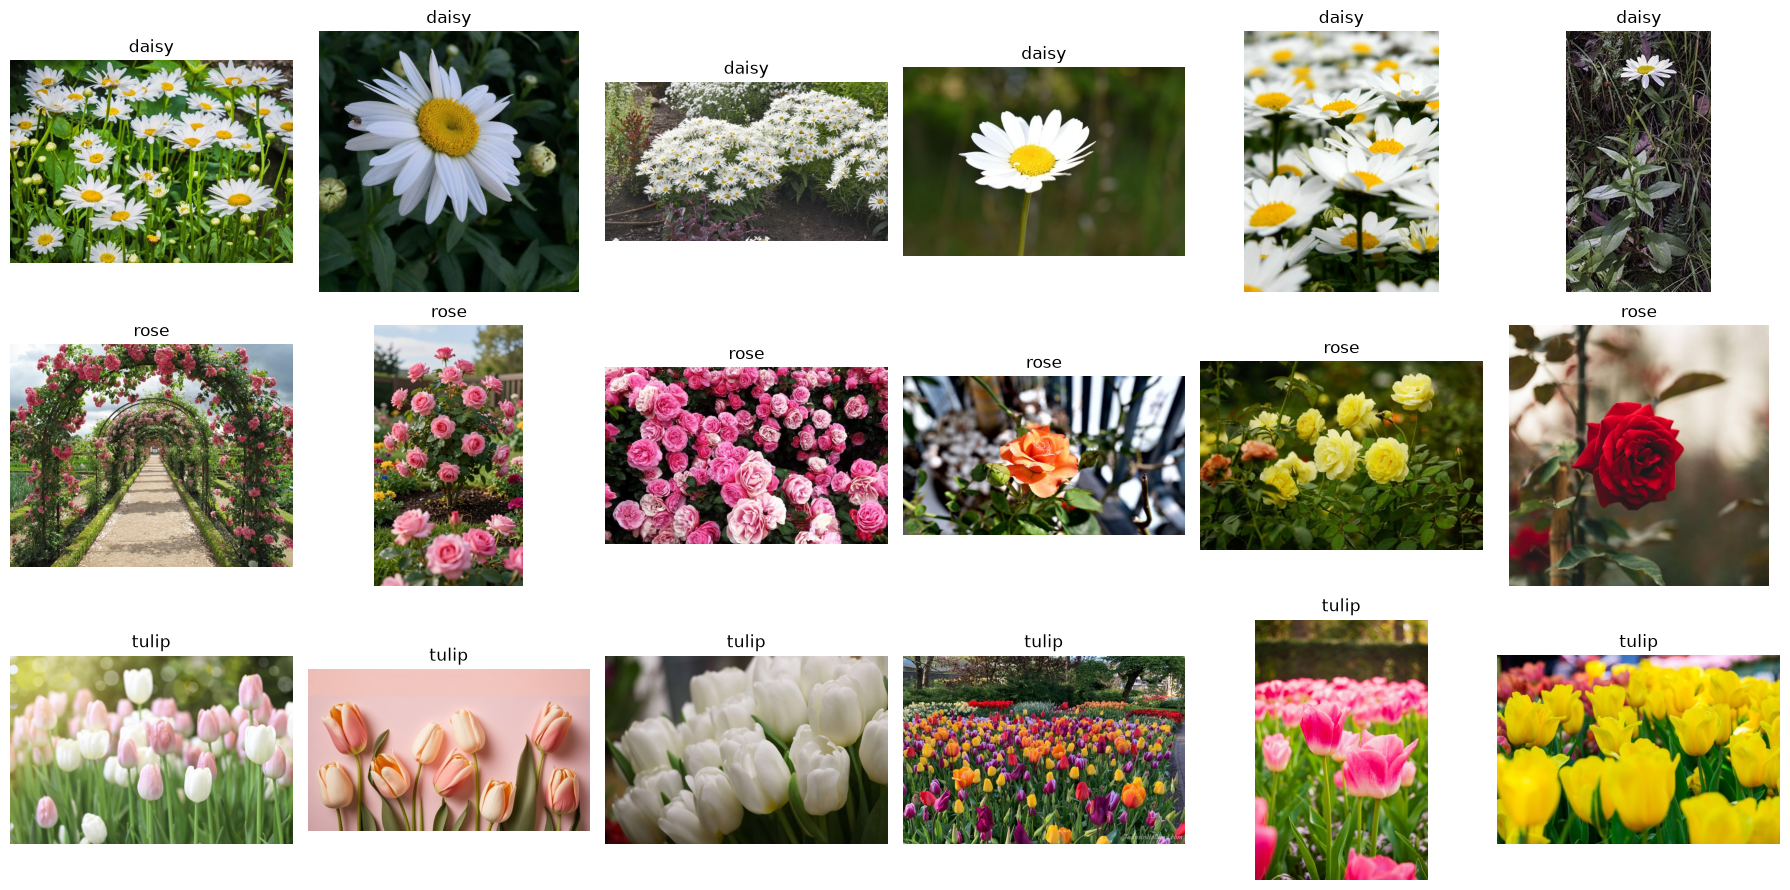

In [9]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Revisión del dataset

Se eliminaron resultados claramente ajenos a las clases, imágenes con texto destacado y duplicados durante la revisión previa al entrenamiento. La lista de exclusiones y sus razones queda en `dataset_review.json`; el conteo efectivo lo genera la celda 12. La validación técnica no reemplaza la revisión visual.

Limitación: las etiquetas provienen de búsquedas y una revisión visual, no de un botánico. Pueden persistir especies visualmente parecidas o imágenes cercanas. El conjunto sirve como experimento académico, no como clasificador botánico validado.

# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [10]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = sorted(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'daisy': 84, 'rose': 103, 'tulip': 102}
validation {'daisy': 18, 'rose': 22, 'tulip': 21}
test {'daisy': 19, 'rose': 23, 'tulip': 23}


### Respuesta

Si se eligen épocas o hiperparámetros mirando test repetidamente, se selecciona indirectamente un modelo adaptado a ese conjunto y la estimación se vuelve optimista. Por eso se fijan antes 20 capas finales, learning rate 1e-5 y hasta 5 épocas de fine-tuning; EarlyStopping usa únicamente validación. Se reporta test antes/después como pide el taller, sin ajustar la receta tras observarlo.

# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [11]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 289 files belonging to 3 classes.


Found 61 files belonging to 3 classes.


Found 65 files belonging to 3 classes.


['daisy', 'rose', 'tulip']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [12]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

**Predicción:** la cabeza debería aprender rápidamente porque ImageNet aporta características de flores. Si train mejora mientras val_loss sube, habrá evidencia de sobreajuste. Se mantiene la base congelada durante esta fase.

In [13]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
history = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[early_stopping], verbose=2)

Epoch 1/10


/Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/work/venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 - 8s - 811ms/step - accuracy: 0.5882 - loss: 0.9232 - val_accuracy: 0.8852 - val_loss: 0.6001


Epoch 2/10


10/10 - 5s - 452ms/step - accuracy: 0.8062 - loss: 0.6021 - val_accuracy: 0.9508 - val_loss: 0.3924


...

10/10 - 4s - 432ms/step - accuracy: 0.9343 - loss: 0.2517 - val_accuracy: 0.9344 - val_loss: 0.1866


Epoch 9/10


10/10 - 4s - 434ms/step - accuracy: 0.9343 - loss: 0.2305 - val_accuracy: 0.9344 - val_loss: 0.1792


Epoch 10/10


10/10 - 4s - 431ms/step - accuracy: 0.9516 - loss: 0.2077 - val_accuracy: 0.9344 - val_loss: 0.1662


### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

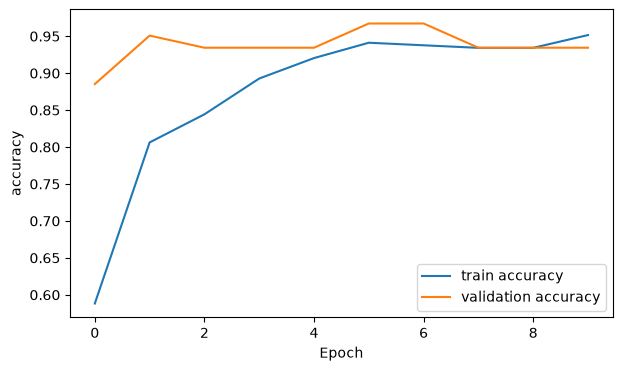

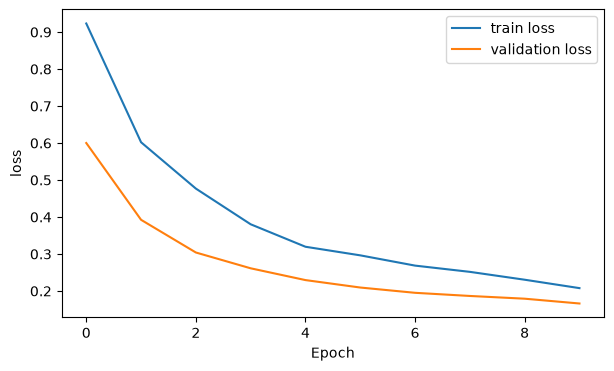

In [14]:
for metric in ["accuracy", "loss"]:
    plt.figure(figsize=(7,4))
    plt.plot(history.history[metric], label="train " + metric)
    plt.plot(history.history["val_" + metric], label="validation " + metric)
    plt.xlabel("Epoch"); plt.ylabel(metric); plt.legend(); plt.show()

# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [x] 3 clases definidas;
- [x] términos de búsqueda documentados;
- [x] imágenes descargadas;
- [x] dataset inspeccionado y parcialmente limpiado;
- [x] separación `train / validation / test`;
- [x] EfficientNetB0 con pesos de ImageNet;
- [x] backbone congelado;
- [x] nueva cabeza de clasificación;
- [x] al menos un entrenamiento completado;
- [x] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [15]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 0.9385


              precision    recall  f1-score   support

       daisy      1.000     1.000     1.000        19
        rose      0.880     0.957     0.917        23
       tulip      0.952     0.870     0.909        23

    accuracy                          0.938        65
   macro avg      0.944     0.942     0.942        65
weighted avg      0.941     0.938     0.938        65



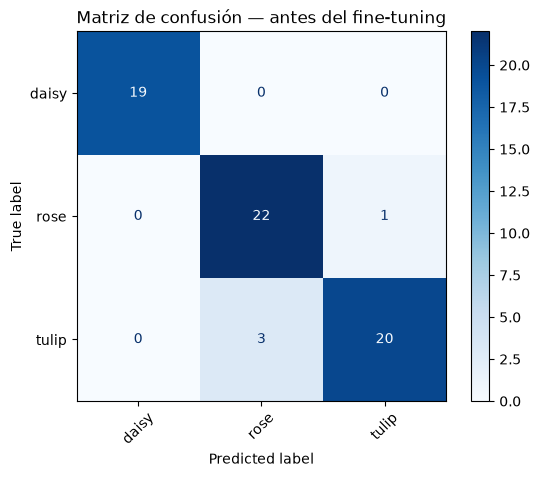

In [16]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()
probabilities_before = probabilities.copy()
y_pred_before = y_pred.copy()

## Interpretación de la evaluación

La celda de informe al final calcula la clase con mayor F1, la confusión más frecuente y las métricas por clase para ambos modelos. Una accuracy global alta puede ocultar menor recall en una clase; por eso se comparan precision, recall y F1 por separado.

Antes de cambiar arquitectura, revisaría etiquetas ambiguas, duplicados y fondos asociados a una clase; añadiría tomas variadas de las clases con menor recall. Las conclusiones numéricas se escriben después de la ejecución, sin inventar resultados.

# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [17]:
base_model.trainable = True

# TODO 5 — Decide cuántas capas finales adaptar.
# Empieza con ~20. Puedes justificar otro valor usando validation.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

**Decisión fijada previamente:** descongelar 20 capas finales limita la cantidad de parámetros adaptados con pocos datos. Se conserva BatchNormalization y se elige la mejor época con val_loss. Se contrasta el mínimo de val_loss de ambas fases; no se busca otra configuración usando test.

In [18]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
early_stopping_ft = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
history_ft = model.fit(train_ds, validation_data=val_ds, epochs=5,
    callbacks=[early_stopping_ft], verbose=2)

Epoch 1/5


/Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/work/venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 - 9s - 855ms/step - accuracy: 0.9516 - loss: 0.1981 - val_accuracy: 0.9508 - val_loss: 0.1583


Epoch 2/5


10/10 - 5s - 481ms/step - accuracy: 0.9412 - loss: 0.1934 - val_accuracy: 0.9508 - val_loss: 0.1533


...

10/10 - 5s - 487ms/step - accuracy: 0.9723 - loss: 0.1747 - val_accuracy: 0.9508 - val_loss: 0.1487


Epoch 4/5


10/10 - 5s - 497ms/step - accuracy: 0.9446 - loss: 0.1775 - val_accuracy: 0.9508 - val_loss: 0.1459


Epoch 5/5


10/10 - 5s - 506ms/step - accuracy: 0.9585 - loss: 0.1662 - val_accuracy: 0.9344 - val_loss: 0.1455


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [19]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 0.9385
Después del fine-tuning: 0.9692
Diferencia              : +0.0308


              precision    recall  f1-score   support

       daisy      1.000     1.000     1.000        19
        rose      0.957     0.957     0.957        23
       tulip      0.957     0.957     0.957        23

    accuracy                          0.969        65
   macro avg      0.971     0.971     0.971        65
weighted avg      0.969     0.969     0.969        65



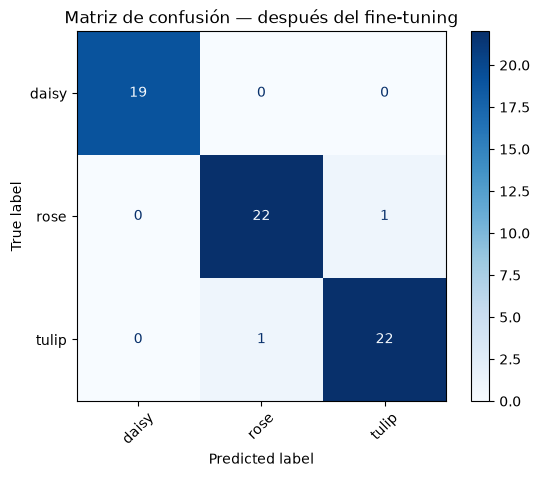

In [20]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

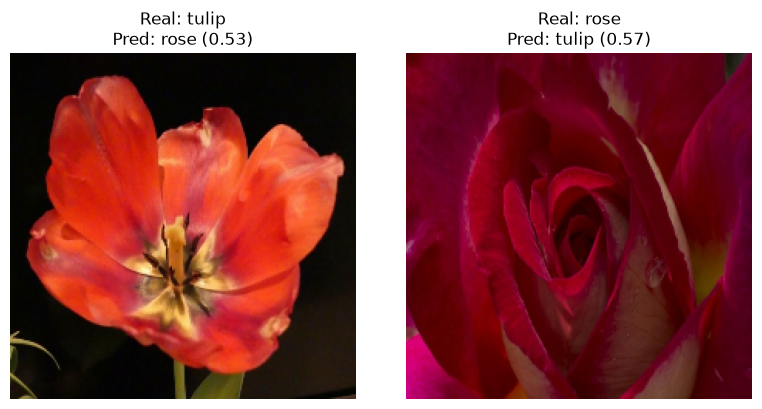

In [21]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

## Análisis de errores y conclusiones

La tabla con errores reales, causas probables y mejoras se añade después de ejecutar. Las causas son hipótesis visuales, no explicaciones causales verificadas del modelo.

**Lo aprendido:** construir un dataset requiere controlar etiquetas y procedencia; descargar archivos técnicamente válidos no garantiza ejemplos correctos. El principal riesgo es confundir flores semejantes y aprovechar fondos o colores asociados a una clase.

**Decisión siguiente:** mejorar datos y diversidad primero. El cambio de accuracy y la comparación de pérdidas de validación se generan en el informe siguiente. Una mejora pequeña puede depender de unas pocas imágenes: no se generaliza a otros dominios sin nueva evaluación.

# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [22]:
# OPCIONAL
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
# response.raise_for_status()
# img = Image.open(io.BytesIO(response.content)).convert("RGB")
# img_resized = img.resize(IMG_SIZE)
# x = np.array(img_resized, dtype="float32")[None, ...]
# p = model.predict(x, verbose=0)[0]
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
# plt.show()

## Cierre conceptual resuelto

- **Base congelada:** se conservan los filtros aprendidos en ImageNet y solo se aprende la nueva cabeza. El conocimiento visual inicial viene del preentrenamiento.
- **Fine-tuning:** se actualizan además algunas capas finales preentrenadas, con pasos pequeños para adaptarlas a flores sin destruir lo aprendido. Se mantiene BatchNormalization congelada.
- **Desde cero:** filtros y clasificador empiezan aleatoriamente; todo debe aprenderse de este dataset. Exige más datos y cómputo, y puede sobreajustar mucho con unas centenas de fotos.

# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# Checklist de entrega
El checklist verificado y las conclusiones de esta ejecución se encuentran al final del notebook. Las extensiones opcionales no se incluyen como entregables pendientes.


# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |

In [23]:
import json
from IPython.display import Markdown
Path("reports").mkdir(exist_ok=True)
reports = {}
for phase, predicted in [("before", y_pred_before), ("after", y_pred_ft)]:
    rep = classification_report(y_true, predicted, labels=range(NUM_CLASSES),
        target_names=class_names, output_dict=True, zero_division=0)
    cm_phase = confusion_matrix(y_true, predicted, labels=range(NUM_CLASSES))
    best = max(class_names, key=lambda name: rep[name]["f1-score"])
    errors = cm_phase.copy(); np.fill_diagonal(errors, 0)
    i,j = np.unravel_index(np.argmax(errors), errors.shape)
    confusion = f"{class_names[i]} → {class_names[j]} ({errors[i,j]} casos)" if errors.max() else "Ninguna"
    reports[phase] = rep
    display(Markdown(f"**{phase}:** mejor F1: {best} ({rep[best]['f1-score']:.3f}); confusión principal: {confusion}."))
summary = {"classes":class_names, "counts":{s:count_images(SPLIT_DIR/s) for s in ["train","validation","test"]},
    "accuracy_before":float(test_acc_before),"accuracy_after":float(test_acc_after),
    "best_val_loss_before":float(min(history.history["val_loss"])),
    "best_val_loss_after":float(min(history_ft.history["val_loss"])), "reports":reports}
Path("reports/transfer_results.json").write_text(json.dumps(summary, indent=2))
display(Markdown(f"**Cambio observado:** {test_acc_before:.2%} → {test_acc_after:.2%} "
    f"({test_acc_after-test_acc_before:+.2%}). Mínimos de val_loss: "
    f"{min(history.history['val_loss']):.4f} → {min(history_ft.history['val_loss']):.4f}."))
# Correspondencia de archivos estable: test se cargó sin shuffle.
test_files = [p for label in class_names for p in sorted((SPLIT_DIR/"test"/label).glob("*.jpg"))]
assert len(test_files) == len(y_true)
error_records = []
for i,(true,pred) in enumerate(zip(y_true,y_pred_ft)):
    if true != pred:
        error_records.append({"file":str(test_files[i]),"true":class_names[int(true)],
          "prediction":class_names[int(pred)], "confidence":float(probabilities_ft[i,pred])})
Path("reports/errors.json").write_text(json.dumps(error_records, indent=2))
print("Errores reales disponibles para inspección:", len(error_records))

**before:** mejor F1: daisy (1.000); confusión principal: tulip → rose (3 casos).

**after:** mejor F1: daisy (1.000); confusión principal: rose → tulip (1 casos).

**Cambio observado:** 93.85% → 96.92% (+3.08%). Mínimos de val_loss: 0.1662 → 0.1455.

Errores reales disponibles para inspección: 2


In [24]:
# Evidencia adicional de errores: test antes/después y validación después.
# No se usa esta inspección para reajustar el modelo ni volver a medir test.
all_errors = []
for phase, split, truths, preds, probs in [
    ("before", "test", y_true, y_pred_before, probabilities_before),
    ("after", "test", y_true_ft, y_pred_ft, probabilities_ft),
    ("after", "validation", *get_predictions(model, val_ds))]:
    files = [p for label in class_names for p in sorted((SPLIT_DIR/split/label).glob("*.jpg"))]
    for i,(true,pred) in enumerate(zip(truths,preds)):
        if true != pred:
            all_errors.append({"phase":phase,"split":split,"file":str(files[i]),
                "true":class_names[int(true)],"prediction":class_names[int(pred)],
                "confidence":float(probs[i,pred])})
Path("reports/all_errors.json").write_text(json.dumps(all_errors, indent=2))
model.save("reports/flowers_finetuned.keras")
print("Errores registrados:", len(all_errors))
print("Imágenes diferentes:", len({row["file"] for row in all_errors}))


Errores registrados: 10
Imágenes diferentes: 8


## Análisis visual de ocho imágenes con error

En test hubo **4 errores antes** y **2 después**. Para analizar al menos cinco imágenes diferentes sin inventar fallos, se incluyen los cuatro casos del test inicial y cuatro errores de validación del modelo final. Se indica la fase y partición de cada caso. Esta inspección es posterior a fijar el entrenamiento y no se usa para reajustar parámetros.

| Archivo | Fase / conjunto | Real → predicción | Causa probable observada | Mejora propuesta |
|---|---|---|---|---|
| rose/0039.jpg | Antes y después / test | Rosa → tulipán | Primer plano oscuro de pétalos rojos: se distinguen pocos bordes internos | Añadir rosas oscuras con iluminación variable |
| tulip/0100.jpg | Antes / test | Tulipán → rosa | Ramo de botones rosados con fondo muy desenfocado; puede parecer un ramo de capullos de rosa | Más ejemplos de tulipanes cerrados y ramos |
| tulip/0127.jpg | Antes / test | Tulipán → rosa | Flor roja muy abierta; pierde la silueta típica de copa | Incluir tulipanes abiertos vistos desde arriba |
| tulip/0139.jpg | Antes y después / test | Tulipán → rosa | Pétalos abiertos e irregulares; forma menos representativa | Diversificar variedades y etapas de apertura |
| daisy/0064.jpg | Después / validación | Margarita → tulipán | Flores pequeñas contra cielo; el fondo ocupa gran parte de la imagen | Incorporar escalas variadas o recortar el objeto |
| rose/0013.jpg | Después / validación | Rosa → tulipán | Vista lateral de rosa rosada; pétalos abiertos y vegetación dominante | Añadir vistas laterales y fondos distintos |
| rose/0080.jpg | Después / validación | Rosa → tulipán | Flores amarillas vistas desde abajo contra cielo azul | Diversificar color y punto de vista en todas las clases |
| rose/0120.jpg | Después / validación | Rosa → tulipán | Recorte extremo de pétalos rojos con bordes rizados | Añadir primeros planos y revisar ejemplares ambiguos |

Las causas son hipótesis visuales, no una medición causal de qué usó la red.

![Errores inspeccionados](reports/errores_inspeccionados.jpg)

### Conclusión basada en la ejecución

Se conservaron **121 margaritas, 148 rosas y 146 tulipanes**, con 289 imágenes de entrenamiento, 61 de validación y 65 de prueba. Las consultas iniciales trajeron jardines lejanos, otras flores, ilustraciones y fichas de producto. Refinar las consultas y revisar las imágenes fue más útil que acumular resultados indiscriminadamente. Se excluyeron 19 imágenes y se documentaron las razones.

La accuracy de test pasó de **61/65 = 93,85 %** a **63/65 = 96,92 %**, una mejora de **3,08 puntos porcentuales**, equivalente a dos imágenes. El mínimo de val_loss bajó de **0,1662 a 0,1455**, lo que respalda el ajuste sin usar test para elegir configuración. Margarita tuvo F1=1 en test; rosas y tulipanes tuvieron F1=0,9565 después del ajuste. Antes, el recall de tulipanes era 0,8696: el accuracy global ocultaba parte de esa dificultad.

El fine-tuning ayudó en esta partición, pero 65 imágenes y una sola semilla no demuestran una mejora general. Los dos errores finales fueron una rosa confundida con tulipán y un tulipán confundido con rosa. Mejoraría primero diversidad y calidad de datos; después evaluaría nuevas configuraciones usando validación o un conjunto externo nuevo.

### Checklist verificado

- [x] Tres clases, consultas y procedencia documentadas.
- [x] Dataset revisado y separado en train/validation/test.
- [x] EfficientNetB0 de ImageNet y cabeza entrenada con base congelada.
- [x] Curvas, evaluación, precision/recall/F1 y matrices de confusión.
- [x] Fine-tuning y comparación real antes/después.
- [x] Ocho imágenes con error inspeccionadas, indicando fase y conjunto.
- [x] Conclusiones conceptuales y empíricas.
